# 02 · Exploratory Data Analysis (EDA)
**Project:** Retail Shop Analysis Using Data Analytics

This notebook answers the core business questions using the cleaned dataset:

1. Headline KPIs: revenue, profit, orders, average order value
2. Time trends: yearly, quarterly, monthly, seasonality
3. Product and category performance
4. Regional (province) performance
5. Customer purchasing patterns
6. Discount and shipping impact on profitability
7. Inventory and stock movement patterns (ABC analysis, product velocity)

Every chart is saved to `visualizations/`, and every headline number is saved to
`results/eda_metrics.json` so the report uses exactly the same figures.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import viz_style as vs

vs.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

df = pd.read_csv("../dataset/cleaned_data.csv", parse_dates=["order_date", "ship_date"])
df["discount_band"] = pd.Categorical(df["discount_band"], ["0-2%", "3-5%", "6-8%", "9%+"], ordered=True)
df["price_band"] = pd.Categorical(df["price_band"], ["Budget (<$20)", "Mid ($20-100)",
                                  "Upper ($100-500)", "Premium ($500+)"], ordered=True)
CATS = ["Technology", "Furniture", "Office Supplies"]
metrics = {}            # all headline numbers collected here
print(df.shape)

(8399, 38)


## 1 · Headline KPIs

In [2]:
total_revenue = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
aov = total_revenue / total_orders
kpis = {
    "total_revenue": round(total_revenue, 2),
    "total_profit": round(total_profit, 2),
    "profit_margin_pct": round(total_profit / total_revenue * 100, 2),
    "total_orders": int(total_orders),
    "total_line_items": int(len(df)),
    "total_units": int(df["quantity"].sum()),
    "total_customers": int(df["customer_name"].nunique()),
    "total_products": int(df["product_name"].nunique()),
    "avg_order_value": round(aov, 2),
    "median_order_value": round(df.groupby("order_id")["sales"].sum().median(), 2),
    "avg_items_per_order": round(len(df) / total_orders, 2),
    "avg_discount_pct": round(df["discount"].mean() * 100, 2),
    "total_shipping_cost": round(df["shipping_cost"].sum(), 2),
    "loss_line_share_pct": round((df["profit"] < 0).mean() * 100, 1),
    "avg_ship_days": round(df["ship_days"].mean(), 2),
}
metrics["kpis"] = kpis
pd.Series(kpis).to_frame("value")

,value
total_revenue,"14,915,600.82"
total_profit,"1,521,767.98"
profit_margin_pct,10.20
total_orders,"5,496.00"
total_line_items,"8,399.00"
total_units,"214,777.00"
total_customers,795.00
total_products,"1,263.00"
avg_order_value,"2,713.90"
median_order_value,899.44


In [3]:
# Insight generated from the numbers above (never typed by hand)
print(f"Insight: over 4 years the shop earned ${kpis['total_revenue']/1e6:.2f}M revenue from "
      f"{kpis['total_orders']:,} orders, at a {kpis['profit_margin_pct']:.1f}% profit margin. "
      f"The mean order value (${kpis['avg_order_value']:,.0f}) is far above the median "
      f"(${kpis['median_order_value']:,.0f}), so a minority of large orders carries much of the revenue. "
      f"{kpis['loss_line_share_pct']:.1f}% of line items are sold at a loss.")

Insight: over 4 years the shop earned $14.92M revenue from 5,496 orders, at a 10.2% profit margin. The mean order value ($2,714) is far above the median ($899), so a minority of large orders carries much of the revenue. 50.8% of line items are sold at a loss.


## 2 · Time trends
### 2.1 Yearly comparison

In [4]:
yearly = df.groupby("order_year").agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                      orders=("order_id", "nunique"), units=("quantity", "sum"))
yearly["margin_pct"] = yearly["profit"] / yearly["revenue"] * 100
yearly["aov"] = yearly["revenue"] / yearly["orders"]
yearly["revenue_growth_pct"] = yearly["revenue"].pct_change() * 100
metrics["yearly"] = yearly.round(2).reset_index().to_dict("records")
yearly

,revenue,profit,orders,units,margin_pct,aov,revenue_growth_pct
order_year,,,,,,,
2009,"4,209,139.46","434,538.73",1394,54380,10.32,"3,019.47",NaN
2010,"3,549,680.80","363,871.48",1393,54384,10.25,"2,548.23",-15.67
2011,"3,436,816.70","381,455.99",1317,51564,11.10,"2,609.58",-3.18
2012,"3,719,963.86","341,901.78",1392,54449,9.19,"2,672.39",8.24


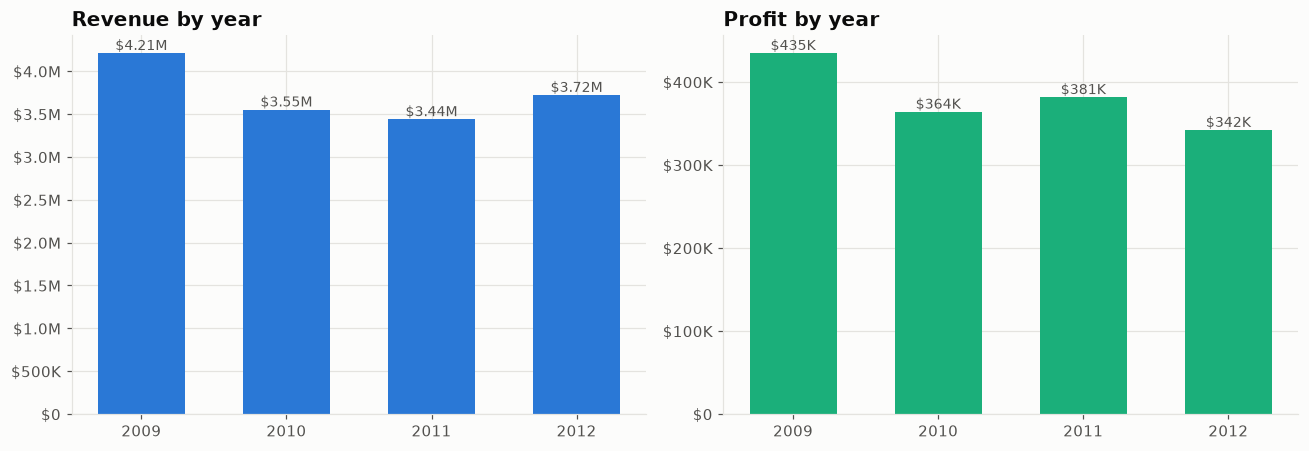

In [5]:
# Two separate panels, one per measure (never a dual axis)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
years = yearly.index.astype(str)
axes[0].bar(years, yearly["revenue"], color=vs.BLUE, width=0.6)
axes[0].set_title("Revenue by year"); vs.money_axis(axes[0])
for x, v in zip(years, yearly["revenue"]):
    axes[0].text(x, v, f"${v/1e6:.2f}M", ha="center", va="bottom", color=vs.TEXT_2, fontsize=9)
axes[1].bar(years, yearly["profit"], color=vs.AQUA, width=0.6)
axes[1].set_title("Profit by year"); vs.money_axis(axes[1])
for x, v in zip(years, yearly["profit"]):
    axes[1].text(x, v, f"${v/1e3:.0f}K", ha="center", va="bottom", color=vs.TEXT_2, fontsize=9)
fig.tight_layout(); vs.save(fig, "02_yearly_revenue_profit.png"); plt.show()

### 2.2 Monthly revenue trend

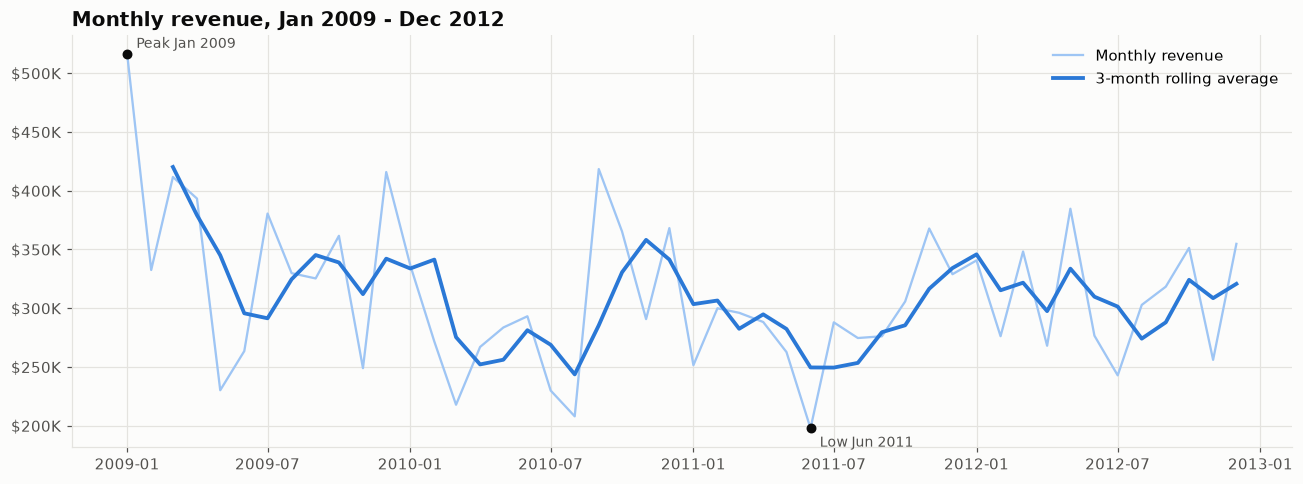

{'best_month': 'Jan 2009',
 'best_month_revenue': np.float64(516302.96),
 'worst_month': 'Jun 2011',
 'worst_month_revenue': np.float64(197740.85),
 'avg_monthly_revenue': np.float64(310741.68),
 'monthly_cv_pct': np.float64(20.5),
 'loss_months': 0}

In [6]:
monthly = (df.set_index("order_date").resample("MS")
           .agg({"sales": "sum", "profit": "sum", "order_id": "nunique"})
           .rename(columns={"sales": "revenue", "order_id": "orders"}))
monthly["rolling_3m"] = monthly["revenue"].rolling(3).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index, monthly["revenue"], color="#9ec5f4", linewidth=1.5, label="Monthly revenue")
ax.plot(monthly.index, monthly["rolling_3m"], color=vs.BLUE, linewidth=2.5, label="3-month rolling average")
best = monthly["revenue"].idxmax(); worst = monthly["revenue"].idxmin()
ax.scatter([best, worst], monthly.loc[[best, worst], "revenue"], color=vs.TEXT, s=30, zorder=3)
ax.annotate(f"Peak {best:%b %Y}", (best, monthly.loc[best, "revenue"]), xytext=(6, 4),
            textcoords="offset points", fontsize=9, color=vs.TEXT_2)
ax.annotate(f"Low {worst:%b %Y}", (worst, monthly.loc[worst, "revenue"]), xytext=(6, -12),
            textcoords="offset points", fontsize=9, color=vs.TEXT_2)
ax.set_title("Monthly revenue, Jan 2009 - Dec 2012"); vs.money_axis(ax); ax.legend(loc="upper right")
fig.tight_layout(); vs.save(fig, "03_monthly_revenue_trend.png"); plt.show()

metrics["monthly"] = {
    "best_month": f"{best:%b %Y}", "best_month_revenue": round(monthly.loc[best, "revenue"], 2),
    "worst_month": f"{worst:%b %Y}", "worst_month_revenue": round(monthly.loc[worst, "revenue"], 2),
    "avg_monthly_revenue": round(monthly["revenue"].mean(), 2),
    "monthly_cv_pct": round(monthly["revenue"].std() / monthly["revenue"].mean() * 100, 1),
    "loss_months": int((monthly["profit"] < 0).sum()),
}
monthly.to_csv("../results/monthly_trend.csv")
metrics["monthly"]

### 2.3 Seasonality: revenue heatmap (year × month)

C:\Users\asus\AppData\Local\Temp\ipykernel_13116\4166383309.py:2: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  season.columns = pd.to_datetime(season.columns, format="%m").strftime("%b")


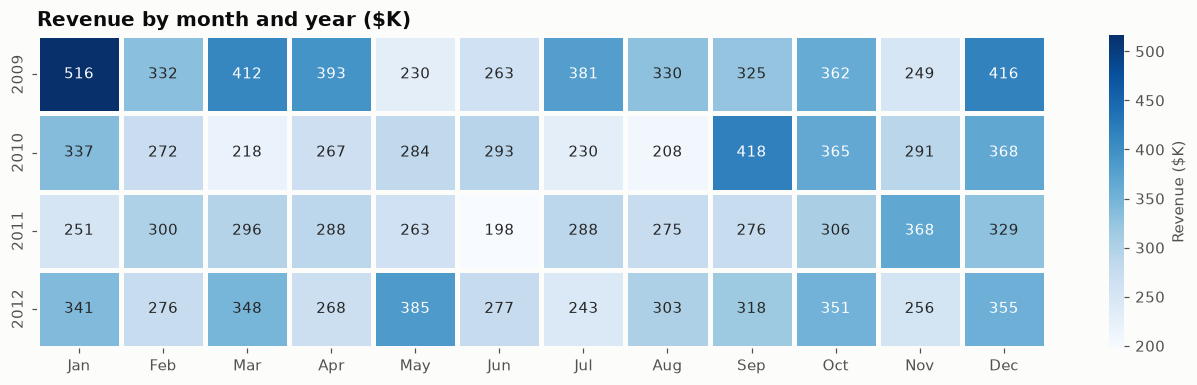

{'strongest_calendar_month': 'December', 'weakest_calendar_month': 'June', 'quarter_share_pct': {'Q1': 26.1, 'Q2': 22.9, 'Q3': 24.1, 'Q4': 26.9}}


order_quarter,Q1,Q2,Q3,Q4
order_year,,,,
2009,"1,260,412.32","886,878.09","1,035,551.00","1,026,298.04"
2010,"825,915.20","843,583.54","856,165.79","1,024,016.28"
2011,"847,393.24","748,582.74","838,533.46","1,002,307.26"
2012,"964,967.33","929,193.97","863,826.39","961,976.17"


In [7]:
season = df.pivot_table(index="order_year", columns="order_month", values="sales", aggfunc="sum")
season.columns = pd.to_datetime(season.columns, format="%m").strftime("%b")
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(season / 1e3, cmap=vs.SEQ_CMAP, annot=True, fmt=".0f", linewidths=2,
            linecolor=vs.SURFACE, cbar_kws={"label": "Revenue ($K)"}, ax=ax)
ax.set_title("Revenue by month and year ($K)"); ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout(); vs.save(fig, "04_seasonality_heatmap.png"); plt.show()

month_avg = df.groupby("order_month")["sales"].sum() / df["order_year"].nunique()
quarter = df.pivot_table(index="order_year", columns="order_quarter", values="sales", aggfunc="sum")
metrics["seasonality"] = {
    "strongest_calendar_month": pd.to_datetime(str(month_avg.idxmax()), format="%m").strftime("%B"),
    "weakest_calendar_month": pd.to_datetime(str(month_avg.idxmin()), format="%m").strftime("%B"),
    "quarter_share_pct": (df.groupby("order_quarter")["sales"].sum() / total_revenue * 100).round(1).to_dict(),
}
print(metrics["seasonality"]); quarter

### 2.4 Quarterly revenue by year

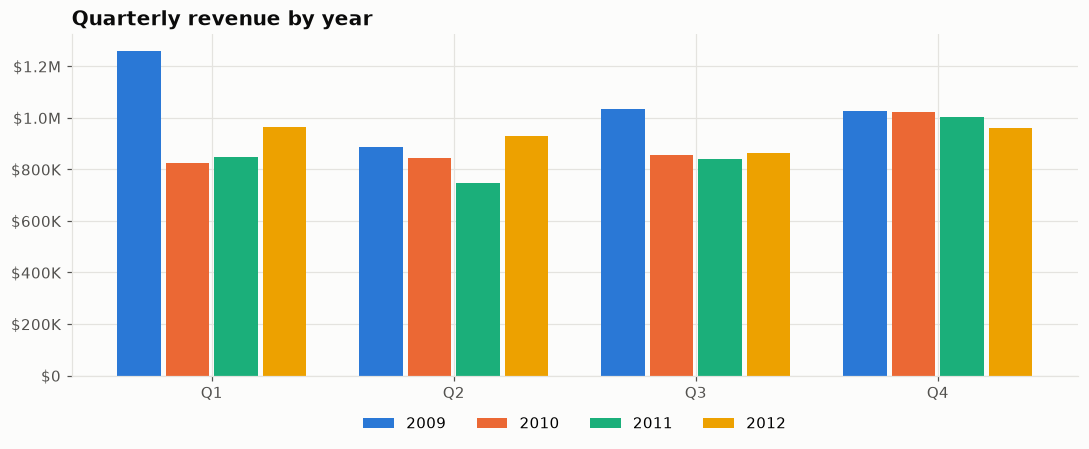

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
qcolors = [vs.BLUE, vs.ORANGE, vs.AQUA, vs.YELLOW]
w = 0.2
for i, (yr, row) in enumerate(quarter.iterrows()):
    ax.bar(np.arange(4) + (i - 1.5) * w, row.values, width=w - 0.02, color=qcolors[i], label=str(yr))
ax.set_xticks(range(4)); ax.set_xticklabels(quarter.columns)
ax.set_title("Quarterly revenue by year"); vs.money_axis(ax)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.tight_layout(); vs.save(fig, "05_quarterly_revenue.png"); plt.show()

## 3 · Category and product performance
### 3.1 Category revenue, profit and margin

In [9]:
cat = df.groupby("category").agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                  units=("quantity", "sum"), line_items=("row_id", "count"))
cat["margin_pct"] = cat["profit"] / cat["revenue"] * 100
cat["revenue_share_pct"] = cat["revenue"] / total_revenue * 100
cat["profit_share_pct"] = cat["profit"] / total_profit * 100
cat = cat.sort_values("revenue", ascending=False)
metrics["category"] = cat.round(2).reset_index().to_dict("records")
cat

,revenue,profit,units,line_items,margin_pct,revenue_share_pct,profit_share_pct
category,,,,,,,
Technology,"5,984,248.18","886,313.52",52175,2065,14.81,40.12,58.24
Furniture,"5,178,590.54","117,433.03",44324,1724,2.27,34.72,7.72
Office Supplies,"3,752,762.10","518,021.43",118278,4610,13.80,25.16,34.04


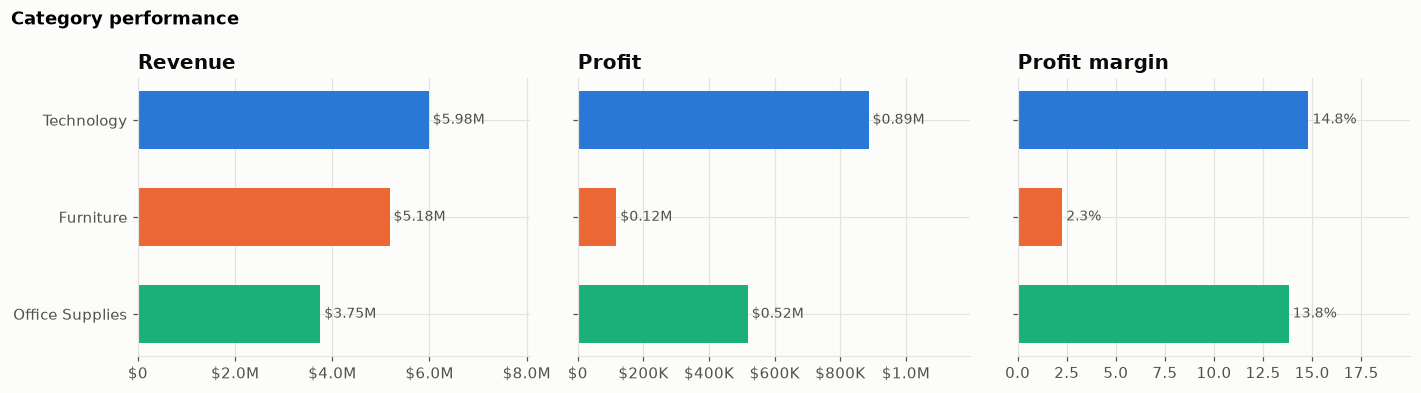

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
colors = [vs.CATEGORY_COLORS[c] for c in cat.index]
for ax, col, title, fmt in [(axes[0], "revenue", "Revenue", lambda v: f"${v/1e6:.2f}M"),
                            (axes[1], "profit", "Profit", lambda v: f"${v/1e6:.2f}M"),
                            (axes[2], "margin_pct", "Profit margin", lambda v: f"{v:.1f}%")]:
    ax.barh(cat.index[::-1], cat[col][::-1], color=colors[::-1], height=0.6)
    ax.set_title(title)
    for y, v in enumerate(cat[col][::-1]):
        ax.text(v, y, " " + fmt(v), va="center", color=vs.TEXT_2, fontsize=9)
    ax.set_xlim(0, cat[col].max() * 1.35)
    if col != "margin_pct": vs.money_axis(ax, "x")
for ax in axes[1:]: ax.set_yticklabels([])
fig.suptitle("Category performance", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); vs.save(fig, "06_category_performance.png"); plt.show()

### 3.2 Sub-category profit (which product lines lose money?)

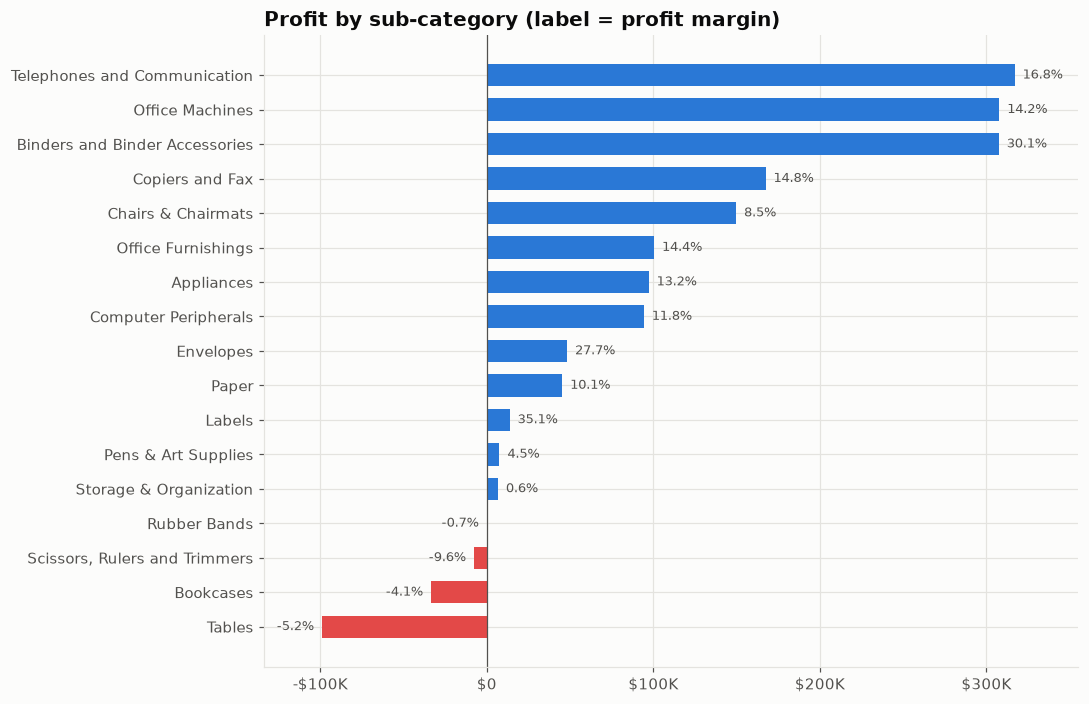

,category,sub_category,revenue,profit,units,avg_discount,margin_pct
15,Technology,Office Machines,"2,168,697.14","307,712.93",7856,0.05,14.19
3,Furniture,Tables,"1,896,008.14","-99,062.50",9195,0.05,-5.22
16,Technology,Telephones and Communication,"1,889,313.80","316,951.62",22969,0.05,16.78
1,Furniture,Chairs & Chairmats,"1,761,836.55","149,649.73",9590,0.05,8.49
14,Technology,Copiers and Fax,"1,130,361.30","167,361.49",2128,0.05,14.81
12,Office Supplies,Storage & Organization,"1,070,182.60","6,664.15",13804,0.05,0.62
5,Office Supplies,Binders and Binder Accessories,"1,022,957.59","307,413.39",22992,0.05,30.05
0,Furniture,Bookcases,"822,652.04","-33,582.13",4891,0.05,-4.08
13,Technology,Computer Peripherals,"795,875.94","94,287.48",19222,0.05,11.85
4,Office Supplies,Appliances,"736,991.54","97,158.06",10901,0.05,13.18


In [11]:
sub = df.groupby(["category", "sub_category"]).agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                                   units=("quantity", "sum"), avg_discount=("discount", "mean"))
sub["margin_pct"] = sub["profit"] / sub["revenue"] * 100
sub = sub.reset_index().sort_values("profit")
metrics["sub_category"] = sub.round(2).to_dict("records")

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(sub["sub_category"], sub["profit"], color=np.where(sub["profit"] >= 0, vs.POS, vs.NEG), height=0.65)
ax.axvline(0, color=vs.TEXT_2, linewidth=0.8)
for y, (p, m) in enumerate(zip(sub["profit"], sub["margin_pct"])):
    ax.text(p, y, f"  {m:.1f}% " if p >= 0 else f"{m:.1f}%  ", va="center",
            ha="left" if p >= 0 else "right", fontsize=8.5, color=vs.TEXT_2)
ax.set_xlim(sub["profit"].min() * 1.35, sub["profit"].max() * 1.12)
ax.set_title("Profit by sub-category (label = profit margin)"); vs.money_axis(ax, "x")
fig.tight_layout(); vs.save(fig, "07_subcategory_profit.png"); plt.show()
sub.sort_values("revenue", ascending=False)

### 3.3 Best-selling products

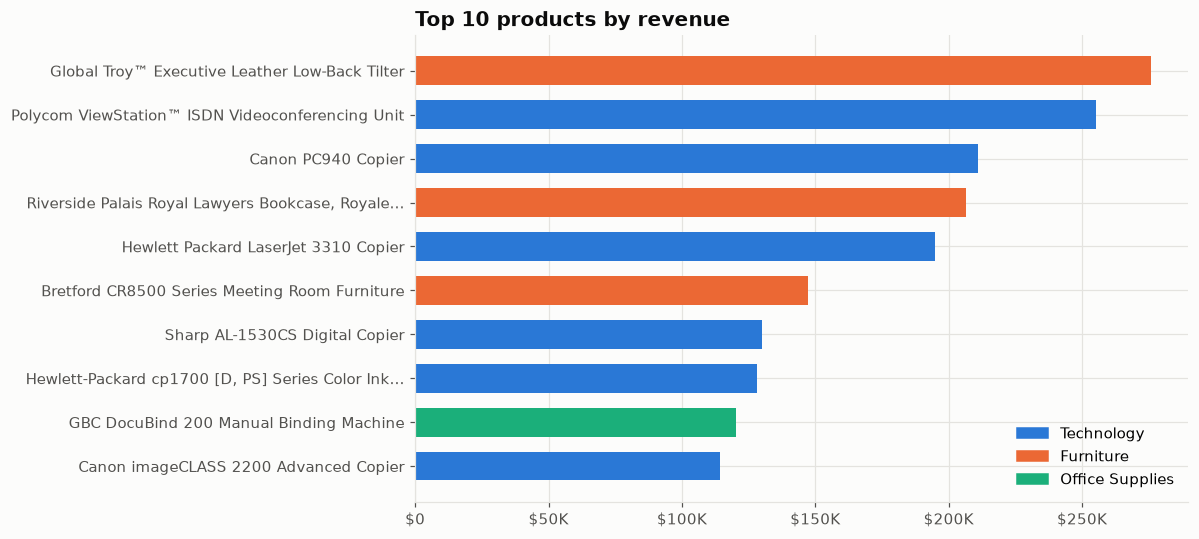

,product_name,category,sub_category,revenue,profit,units,orders,margin_pct
565,Global Troy™ Executive Leather Low-Back Tilter,Furniture,Chairs & Chairmats,"275,941.52","79,284.78",550,17,28.73
860,Polycom ViewStation™ ISDN Videoconferencing Unit,Technology,Office Machines,"255,303.97","-17,771.27",41,7,-6.96
323,Canon PC940 Copier,Technology,Copiers and Fax,"210,910.68","47,705.85",474,18,22.62
895,"Riverside Palais Royal Lawyers Bookcase, Royal...",Furniture,Bookcases,"206,494.13","14,291.57",236,11,6.92
582,Hewlett Packard LaserJet 3310 Copier,Technology,Copiers and Fax,"194,880.35","73,299.61",334,10,37.61
294,Bretford CR8500 Series Meeting Room Furniture,Furniture,Tables,"147,412.21","-1,989.87",407,14,-1.35
946,Sharp AL-1530CS Digital Copier,Technology,Copiers and Fax,"130,046.81","11,770.30",260,11,9.05
591,"Hewlett-Packard cp1700 [D, PS] Series Color In...",Technology,Office Machines,"128,100.43","55,281.39",269,10,43.15
515,GBC DocuBind 200 Manual Binding Machine,Office Supplies,Binders and Binder Accessories,"120,342.74","50,462.53",286,16,41.93
325,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers and Fax,"114,173.41","-31,885.68",32,7,-27.93


In [12]:
prod = df.groupby(["product_name", "category", "sub_category"]).agg(
    revenue=("sales", "sum"), profit=("profit", "sum"), units=("quantity", "sum"),
    orders=("order_id", "nunique")).reset_index()
prod["margin_pct"] = prod["profit"] / prod["revenue"] * 100

def short(s, n=48):
    return s if len(s) <= n else s[:n - 1] + "…"

top_rev = prod.nlargest(10, "revenue")
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top_rev["product_name"].map(short)[::-1], top_rev["revenue"][::-1],
        color=[vs.CATEGORY_COLORS[c] for c in top_rev["category"][::-1]], height=0.65)
ax.set_title("Top 10 products by revenue"); vs.money_axis(ax, "x")
handles = [plt.Rectangle((0, 0), 1, 1, color=vs.CATEGORY_COLORS[c]) for c in CATS]
ax.legend(handles, CATS, loc="lower right")
fig.tight_layout(); vs.save(fig, "08_top10_products_revenue.png"); plt.show()
metrics["top10_products_revenue"] = top_rev.round(2).to_dict("records")
top_rev

In [13]:
top_units = prod.nlargest(10, "units")
metrics["top10_products_units"] = top_units.round(2).to_dict("records")
top_units

,product_name,category,sub_category,revenue,profit,units,orders,margin_pct
557,"Global High-Back Leather Tilter, Burgundy",Furniture,Chairs & Chairmats,"82,752.20","-30,518.90",666,24,-36.88
260,Bevis 36 x 72 Conference Tables,Furniture,Tables,"74,365.63","-7,492.89",619,22,-10.08
1110,"Wilson Jones Hanging View Binder, White, 1""",Office Supplies,Binders and Binder Accessories,"4,259.71","-1,377.27",585,21,-32.33
565,Global Troy™ Executive Leather Low-Back Tilter,Furniture,Chairs & Chairmats,"275,941.52","79,284.78",550,17,28.73
63,"80 Minute CD-R Spindle, 100/Pack - Staples",Technology,Computer Peripherals,"21,617.03","5,534.41",546,20,25.60
749,"Memorex 4.7GB DVD+RW, 3/Pack",Technology,Computer Peripherals,"15,221.28","5,579.35",546,19,36.65
258,Bell Sonecor JB700 Caller ID,Technology,Telephones and Communication,"3,692.88","-1,859.00",537,19,-50.34
740,"Master Giant Foot® Doorstop, Safety Yellow",Furniture,Office Furnishings,"4,039.33",396.36,529,22,9.81
291,BoxOffice By Design Rectangular and Half-Moon ...,Furniture,Tables,"104,483.14","-14,938.68",516,22,-14.30
3,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",Office Supplies,Envelopes,"4,481.17",-833.12,504,17,-18.59


### 3.4 Most profitable and most loss-making products

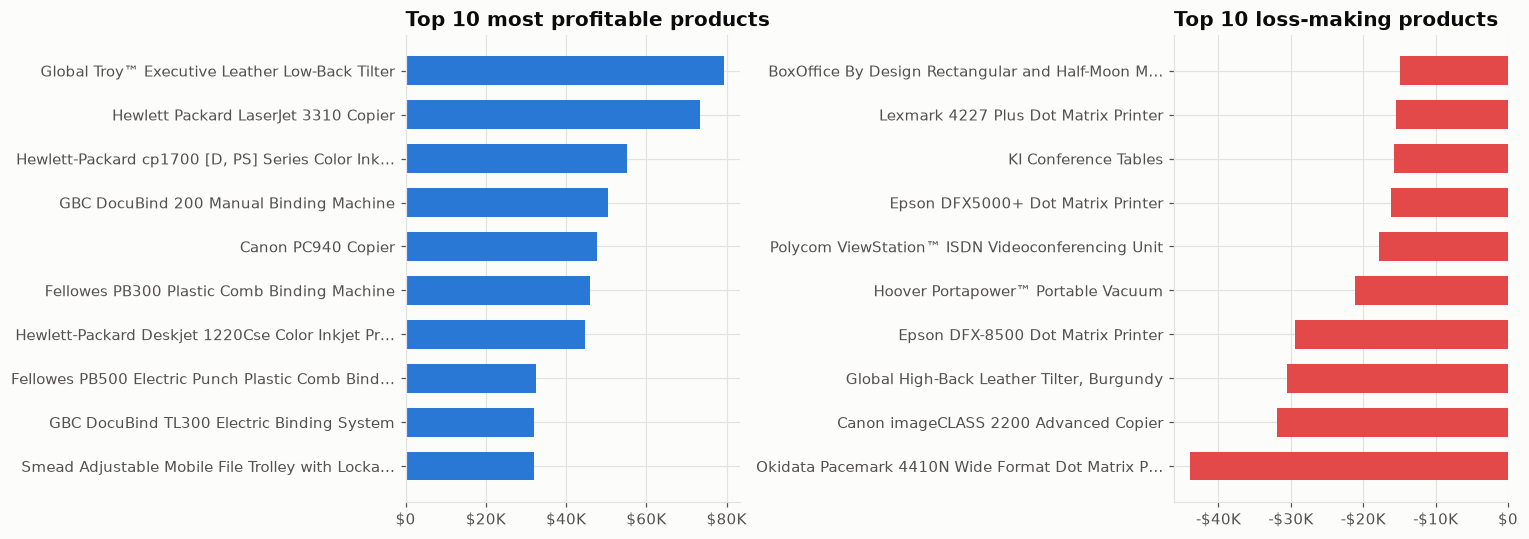

,product_name,category,sub_category,revenue,profit,units,orders,margin_pct
835,Okidata Pacemark 4410N Wide Format Dot Matrix ...,Technology,Office Machines,"60,619.66","-43,949.37",18,6,-72.50
325,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers and Fax,"114,173.41","-31,885.68",32,7,-27.93
557,"Global High-Back Leather Tilter, Burgundy",Furniture,Chairs & Chairmats,"82,752.20","-30,518.90",666,24,-36.88
447,Epson DFX-8500 Dot Matrix Printer,Technology,Office Machines,"85,975.08","-29,400.34",35,7,-34.20
632,Hoover Portapower™ Portable Vacuum,Office Supplies,Appliances,"2,946.43","-21,088.48",465,18,-715.73
860,Polycom ViewStation™ ISDN Videoconferencing Unit,Technology,Office Machines,"255,303.97","-17,771.27",41,7,-6.96
448,Epson DFX5000+ Dot Matrix Printer,Technology,Office Machines,"20,835.42","-16,160.74",14,5,-77.56
689,KI Conference Tables,Furniture,Tables,"23,289.69","-15,701.27",323,13,-67.42
712,Lexmark 4227 Plus Dot Matrix Printer,Technology,Office Machines,"59,735.01","-15,492.81",32,6,-25.94
291,BoxOffice By Design Rectangular and Half-Moon ...,Furniture,Tables,"104,483.14","-14,938.68",516,22,-14.30


In [14]:
top_profit = prod.nlargest(10, "profit")
worst_profit = prod.nsmallest(10, "profit")
metrics["top10_products_profit"] = top_profit.round(2).to_dict("records")
metrics["bottom10_products_profit"] = worst_profit.round(2).to_dict("records")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(top_profit["product_name"].map(short)[::-1], top_profit["profit"][::-1], color=vs.POS, height=0.65)
axes[0].set_title("Top 10 most profitable products"); vs.money_axis(axes[0], "x")
axes[1].barh(worst_profit["product_name"].map(short), worst_profit["profit"], color=vs.NEG, height=0.65)
axes[1].set_title("Top 10 loss-making products"); vs.money_axis(axes[1], "x")
fig.tight_layout(); vs.save(fig, "09_product_profit_loss.png"); plt.show()
worst_profit

### 3.5 Sales distribution by category
The box plot (log scale) shows the spread of line-item sales in each category. The
100% bar shows each category's share of revenue, profit and units.

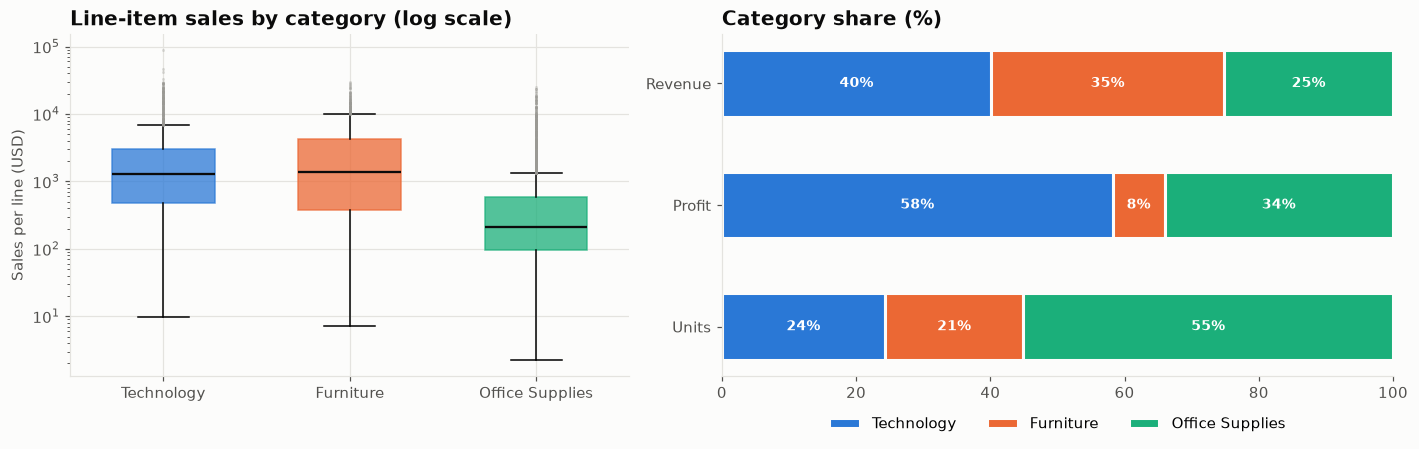

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
data = [df.loc[df["category"] == c, "sales"] for c in CATS]
bp = axes[0].boxplot(data, patch_artist=True, widths=0.55, tick_labels=CATS,
                     medianprops=dict(color=vs.TEXT, linewidth=1.5),
                     flierprops=dict(marker="o", markersize=2, alpha=0.3, markeredgecolor="none",
                                     markerfacecolor=vs.GRAY))
for patch, c in zip(bp["boxes"], CATS):
    patch.set_facecolor(vs.CATEGORY_COLORS[c]); patch.set_alpha(0.75); patch.set_edgecolor(vs.CATEGORY_COLORS[c])
axes[0].set_yscale("log"); axes[0].set_title("Line-item sales by category (log scale)")
axes[0].set_ylabel("Sales per line (USD)")

share = cat.loc[CATS, ["revenue", "profit", "units"]]
share = share / share.sum() * 100
left = np.zeros(3)
for c in CATS:
    axes[1].barh(["Revenue", "Profit", "Units"], share.loc[c].values, left=left,
                 color=vs.CATEGORY_COLORS[c], label=c, height=0.55, edgecolor=vs.SURFACE, linewidth=2)
    for y, (l, v) in enumerate(zip(left, share.loc[c].values)):
        axes[1].text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white",
                     fontsize=9, fontweight="bold")
    left += share.loc[c].values
axes[1].invert_yaxis(); axes[1].set_xlim(0, 100); axes[1].set_title("Category share (%)")
axes[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08)); axes[1].grid(False)
fig.tight_layout(); vs.save(fig, "10_category_distribution.png"); plt.show()

## 4 · Regional and provincial performance
The dataset has no individual store IDs. Each **province** is therefore treated as a regional
sales territory or "store group". This is an assumption, and it is stated in the report.

In [16]:
prov = df.groupby(["region", "province"]).agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                              orders=("order_id", "nunique"),
                                              customers=("customer_name", "nunique")).reset_index()
prov["margin_pct"] = prov["profit"] / prov["revenue"] * 100
prov["aov"] = prov["revenue"] / prov["orders"]
prov["revenue_share_pct"] = prov["revenue"] / total_revenue * 100
prov = prov.sort_values("revenue", ascending=False)
metrics["province"] = prov.round(2).to_dict("records")

region = df.groupby("region").agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                  orders=("order_id", "nunique"))
region["margin_pct"] = region["profit"] / region["revenue"] * 100
region = region.sort_values("revenue", ascending=False)
metrics["region"] = region.round(2).reset_index().to_dict("records")
prov

,region,province,revenue,profit,orders,customers,margin_pct,aov,revenue_share_pct
6,Ontario,Ontario,"3,063,212.48","346,868.54",1235,281,11.32,"2,480.33",20.54
11,West,British Columbia,"1,892,757.78","145,062.13",748,203,7.66,"2,530.42",12.69
10,West,Alberta,"1,704,791.49","151,946.48",590,122,8.91,"2,889.48",11.43
9,Quebec,Quebec,"1,510,195.08","140,426.65",587,170,9.30,"2,572.73",10.12
8,Prairie,Saskatchewan,"1,464,455.82","184,732.96",610,116,12.61,"2,400.75",9.82
7,Prairie,Manitoba,"1,372,848.78","136,427.16",541,146,9.94,"2,537.61",9.20
12,Yukon,Yukon,"975,867.37","73,849.21",396,107,7.57,"2,464.31",6.54
2,Atlantic,Nova Scotia,"817,729.36","85,361.87",347,156,10.44,"2,356.57",5.48
4,Northwest Territories,Northwest Territories,"800,847.33","100,653.08",269,62,12.57,"2,977.13",5.37
0,Atlantic,New Brunswick,"684,211.52","115,351.94",222,44,16.86,"3,082.03",4.59


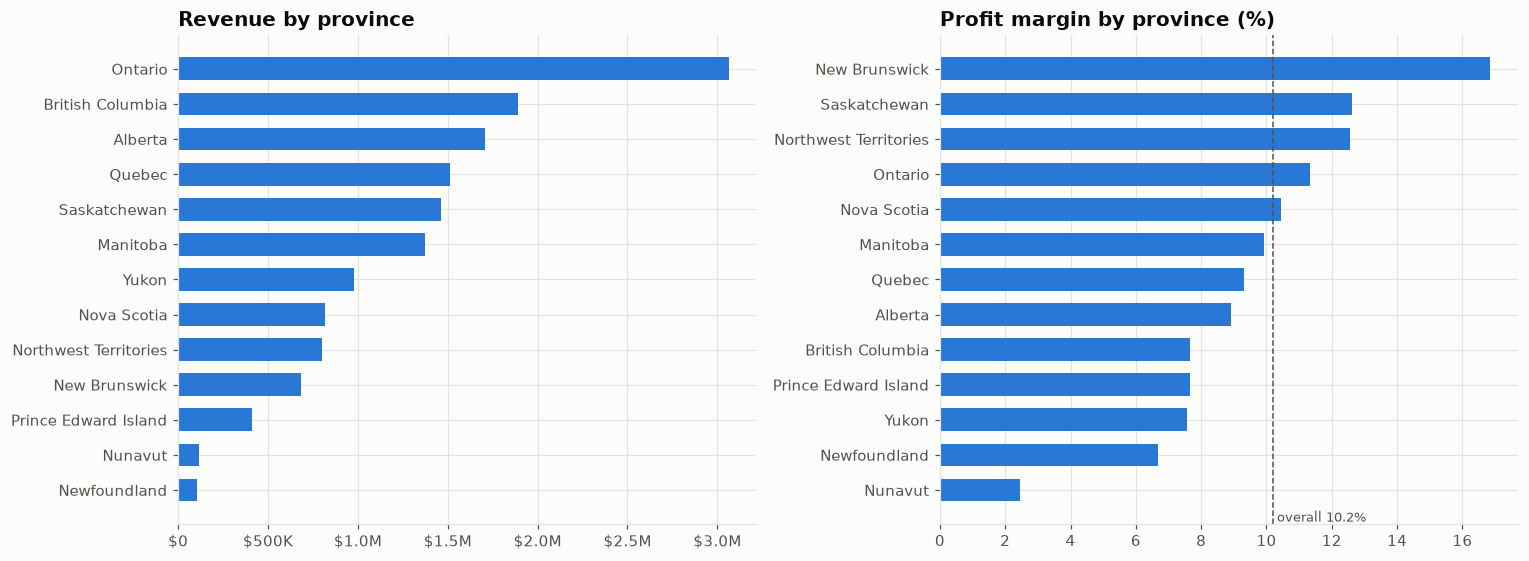

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
p = prov.sort_values("revenue")
axes[0].barh(p["province"], p["revenue"], color=vs.BLUE, height=0.65)
axes[0].set_title("Revenue by province"); vs.money_axis(axes[0], "x")
p = prov.sort_values("margin_pct")
axes[1].barh(p["province"], p["margin_pct"], color=np.where(p["margin_pct"] >= 0, vs.POS, vs.NEG), height=0.65)
axes[1].axvline(kpis["profit_margin_pct"], color=vs.TEXT_2, linestyle="--", linewidth=1)
axes[1].text(kpis["profit_margin_pct"], -0.9, f" overall {kpis['profit_margin_pct']:.1f}%",
             color=vs.TEXT_2, fontsize=8.5)
axes[1].set_title("Profit margin by province (%)")
fig.tight_layout(); vs.save(fig, "11_province_performance.png"); plt.show()

### 4.1 Region × category: where does each category sell best?

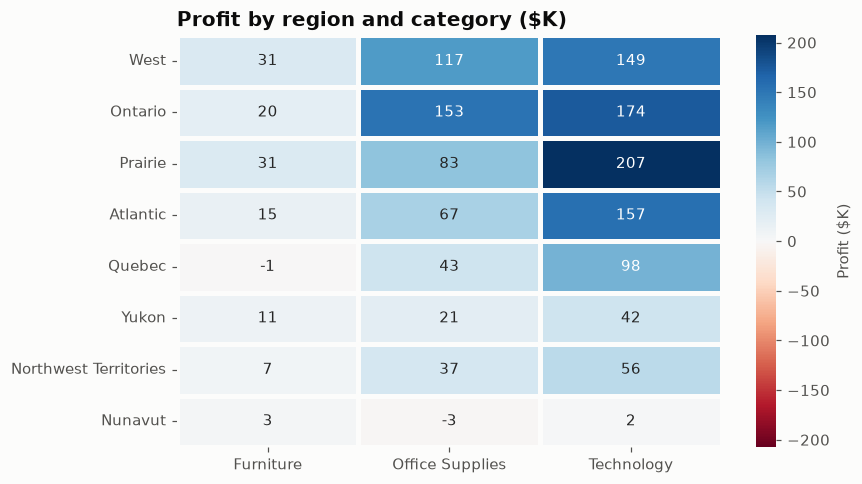

In [18]:
rc = df.pivot_table(index="region", columns="category", values="profit", aggfunc="sum").loc[region.index]
fig, ax = plt.subplots(figsize=(8, 4.5))
lim = np.abs(rc.values).max()
sns.heatmap(rc / 1e3, cmap="RdBu", center=0, vmin=-lim / 1e3, vmax=lim / 1e3, annot=True, fmt=".0f",
            linewidths=2, linecolor=vs.SURFACE, cbar_kws={"label": "Profit ($K)"}, ax=ax)
ax.set_title("Profit by region and category ($K)"); ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout(); vs.save(fig, "12_region_category_profit.png"); plt.show()
metrics["region_category_profit"] = (rc.round(2)).to_dict()

## 5 · Customer purchasing patterns

In [19]:
seg = df.groupby("segment").agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                orders=("order_id", "nunique"), customers=("customer_name", "nunique"))
seg["aov"] = seg["revenue"] / seg["orders"]
seg["margin_pct"] = seg["profit"] / seg["revenue"] * 100
seg["revenue_share_pct"] = seg["revenue"] / total_revenue * 100
seg = seg.sort_values("revenue", ascending=False)
metrics["segment"] = seg.round(2).reset_index().to_dict("records")
seg

,revenue,profit,orders,customers,aov,margin_pct,revenue_share_pct
segment,,,,,,,
Corporate,"5,498,904.88","599,746.00",2002,353,"2,746.71",10.91,36.87
Home Office,"3,564,763.88","318,354.03",1341,246,"2,658.29",8.93,23.90
Consumer,"3,063,611.08","287,959.94",1076,197,"2,847.22",9.40,20.54
Small Business,"2,788,320.99","315,708.01",1077,193,"2,588.97",11.32,18.69


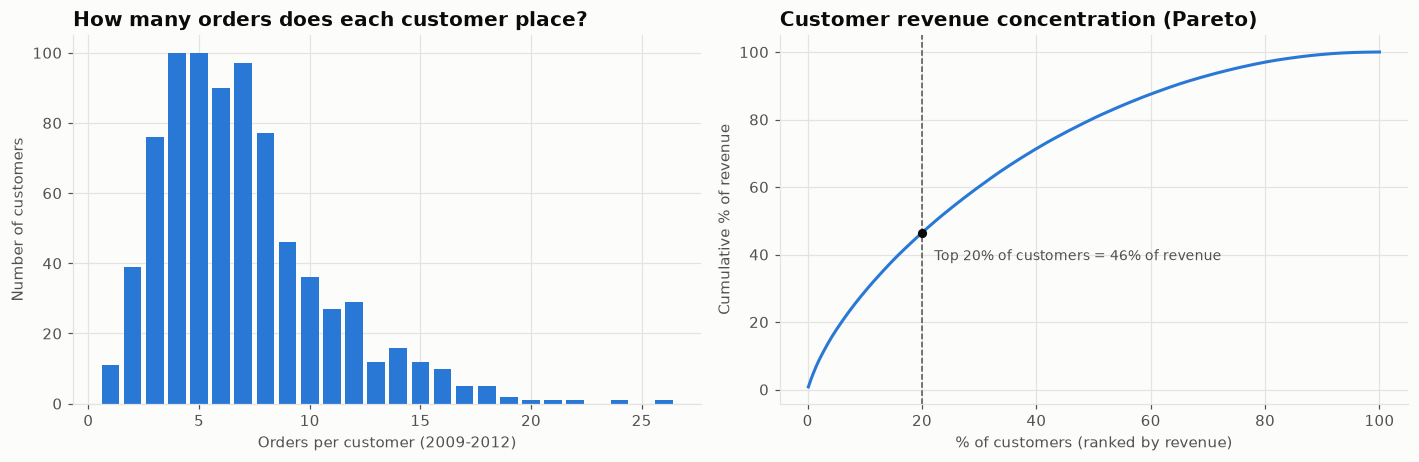

{'n_customers': 795, 'repeat_customer_pct': np.float64(98.6), 'one_time_customers': 11, 'avg_orders_per_customer': np.float64(6.94), 'median_orders_per_customer': 6.0, 'top20pct_customer_revenue_share': np.float64(46.5), 'avg_revenue_per_customer': np.float64(18761.76), 'loss_making_customers': 225}


,revenue,profit,orders,cum_share
customer_name,,,,
Emily Phan,"117,124.44","34,005.44",8,0.79
Deborah Brumfield,"97,433.14","31,121.22",12,1.44
Roy Skaria,"92,542.15","1,343.94",18,2.06
Sylvia Foulston,"88,875.76","5,141.90",18,2.65
Grant Carroll,"88,417.00","27,977.29",17,3.25
Alejandro Grove,"83,561.93","20,588.92",9,3.81
Darren Budd,"81,577.34","1,857.66",26,4.35
Julia Barnett,"80,044.45","-1,956.09",12,4.89
John Lucas,"79,696.19","12,725.08",14,5.43


In [20]:
cust = df.groupby("customer_name").agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                       orders=("order_id", "nunique"))
cust = cust.sort_values("revenue", ascending=False)
cust["cum_share"] = cust["revenue"].cumsum() / cust["revenue"].sum() * 100
top20_n = int(np.ceil(len(cust) * 0.2))
top20_share = cust["revenue"].iloc[:top20_n].sum() / cust["revenue"].sum() * 100
repeat_share = (cust["orders"] > 1).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
counts = cust["orders"].value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=vs.BLUE, width=0.8)
axes[0].set_title("How many orders does each customer place?")
axes[0].set_xlabel("Orders per customer (2009-2012)"); axes[0].set_ylabel("Number of customers")
x = np.arange(1, len(cust) + 1) / len(cust) * 100
axes[1].plot(x, cust["cum_share"].values, color=vs.BLUE)
axes[1].axvline(20, color=vs.TEXT_2, linestyle="--", linewidth=1)
axes[1].scatter([20], [top20_share], color=vs.TEXT, zorder=3, s=25)
axes[1].annotate(f"Top 20% of customers = {top20_share:.0f}% of revenue", (20, top20_share),
                 xytext=(8, -18), textcoords="offset points", fontsize=9, color=vs.TEXT_2)
axes[1].set_title("Customer revenue concentration (Pareto)")
axes[1].set_xlabel("% of customers (ranked by revenue)"); axes[1].set_ylabel("Cumulative % of revenue")
fig.tight_layout(); vs.save(fig, "13_customer_patterns.png"); plt.show()

metrics["customers"] = {
    "n_customers": int(len(cust)),
    "repeat_customer_pct": round(repeat_share, 1),
    "one_time_customers": int((cust["orders"] == 1).sum()),
    "avg_orders_per_customer": round(cust["orders"].mean(), 2),
    "median_orders_per_customer": float(cust["orders"].median()),
    "top20pct_customer_revenue_share": round(top20_share, 1),
    "avg_revenue_per_customer": round(cust["revenue"].mean(), 2),
    "loss_making_customers": int((cust["profit"] < 0).sum()),
}
metrics["top10_customers"] = cust.head(10).round(2).reset_index().to_dict("records")
print(metrics["customers"]); cust.head(10)

In [21]:
# Purchasing behaviour: order priority and ship mode preferences
pri = df.groupby("order_priority").agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                       orders=("order_id", "nunique"))
pri["margin_pct"] = pri["profit"] / pri["revenue"] * 100
ship = df.groupby("ship_mode").agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                   line_items=("row_id", "count"), shipping_cost=("shipping_cost", "sum"),
                                   avg_ship_days=("ship_days", "mean"))
ship["margin_pct"] = ship["profit"] / ship["revenue"] * 100
ship["shipping_cost_pct_of_sales"] = ship["shipping_cost"] / ship["revenue"] * 100
metrics["ship_mode"] = ship.round(2).reset_index().to_dict("records")
metrics["order_priority"] = pri.round(2).reset_index().to_dict("records")
display(pri); ship

,revenue,profit,orders,margin_pct
order_priority,,,,
Critical,"2,724,798.67","182,876.87",1090,6.71
High,"3,267,356.36","407,069.65",1137,12.46
Low,"3,282,630.38","386,184.90",1124,11.76
Medium,"2,862,452.12","327,051.73",1075,11.43
Not Specified,"2,778,363.30","218,584.83",1080,7.87


,revenue,profit,line_items,shipping_cost,avg_ship_days,margin_pct,shipping_cost_pct_of_sales
ship_mode,,,,,,,
Delivery Truck,"6,224,878.72","269,644.87",1146,"51,971.94",2.04,4.33,0.83
Express Air,"1,184,418.90","147,430.31",983,"7,850.91",2.00,12.45,0.66
Regular Air,"7,506,303.21","1,104,692.80",6270,"48,008.19",2.04,14.72,0.64


## 6 · Discount impact on profitability

In [22]:
disc = df.groupby("discount_band", observed=True).agg(
    line_items=("row_id", "count"), revenue=("sales", "sum"), profit=("profit", "sum"),
    loss_lines=("profit", lambda s: (s < 0).sum()))
disc["margin_pct"] = disc["profit"] / disc["revenue"] * 100
disc["loss_line_pct"] = disc["loss_lines"] / disc["line_items"] * 100
metrics["discount"] = disc.round(2).reset_index().astype({"discount_band": str}).to_dict("records")
metrics["discount_profit_corr"] = round(df["discount"].corr(df["profit_margin_pct"], method="spearman"), 3)
disc

,line_items,revenue,profit,loss_lines,margin_pct,loss_line_pct
discount_band,,,,,,
0-2%,2327,"4,344,048.33","536,894.93",1098,12.36,47.19
3-5%,2335,"4,082,476.70","479,477.30",1139,11.74,48.78
6-8%,2209,"3,983,044.76","317,327.63",1170,7.97,52.97
9%+,1528,"2,506,031.03","188,068.12",857,7.50,56.09


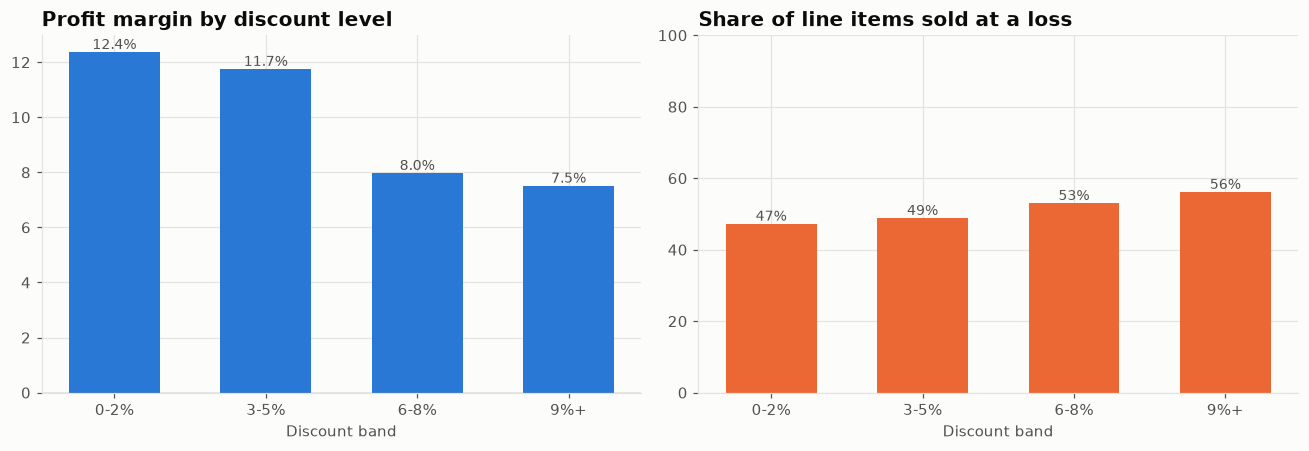

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bands = disc.index.astype(str)
axes[0].bar(bands, disc["margin_pct"], color=np.where(disc["margin_pct"] >= 0, vs.POS, vs.NEG), width=0.6)
for x, v in zip(bands, disc["margin_pct"]):
    axes[0].text(x, v, f"{v:.1f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9, color=vs.TEXT_2)
axes[0].axhline(0, color=vs.TEXT_2, linewidth=0.8)
axes[0].set_title("Profit margin by discount level"); axes[0].set_xlabel("Discount band")
axes[1].bar(bands, disc["loss_line_pct"], color=vs.ORANGE, width=0.6)
for x, v in zip(bands, disc["loss_line_pct"]):
    axes[1].text(x, v, f"{v:.0f}%", ha="center", va="bottom", fontsize=9, color=vs.TEXT_2)
axes[1].set_title("Share of line items sold at a loss"); axes[1].set_xlabel("Discount band")
axes[1].set_ylim(0, 100)
fig.tight_layout(); vs.save(fig, "14_discount_impact.png"); plt.show()

**Reading the discount chart.** The discount levels in this data are fairly small (0–25%), and
the margin falls as the discount rises. Discounting is **not** the only driver of losses,
though. Shipping cost and product type matter too. So the next cell looks at the
relationship between shipping cost and profit.

In [24]:
df["ship_cost_ratio_pct"] = df["shipping_cost"] / df["unit_price"] * 100
df["ship_cost_band"] = pd.qcut(df["ship_cost_ratio_pct"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
scb = df.groupby("ship_cost_band", observed=True).agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                                      loss_share=("profit", lambda s: (s < 0).mean() * 100))
scb["margin_pct"] = scb["profit"] / scb["revenue"] * 100
metrics["shipping_cost_band"] = scb.round(2).reset_index().astype({"ship_cost_band": str}).to_dict("records")

price = df.groupby("price_band", observed=True).agg(revenue=("sales", "sum"), profit=("profit", "sum"),
                                                    units=("quantity", "sum"),
                                                    loss_share=("profit", lambda s: (s < 0).mean() * 100))
price["margin_pct"] = price["profit"] / price["revenue"] * 100
metrics["price_band"] = price.round(2).reset_index().astype({"price_band": str}).to_dict("records")
display(scb); price

,revenue,profit,loss_share,margin_pct
ship_cost_band,,,,
Q1 (lowest),"8,298,666.84","1,631,789.82",22.95,19.66
Q2,"3,928,924.77","393,384.50",29.21,10.01
Q3,"2,008,199.95","-162,352.40",54.81,-8.08
Q4 (highest),"679,809.26","-341,053.94",96.37,-50.17


,revenue,profit,units,loss_share,margin_pct
price_band,,,,,
Budget (<$20),"827,044.84","-111,928.90",104487,62.71,-13.53
Mid ($20-100),"2,909,895.62","218,503.25",63071,39.09,7.51
Upper ($100-500),"8,293,500.27","1,070,958.49",43415,40.40,12.91
Premium ($500+),"2,885,160.10","344,235.14",3804,40.61,11.93


## 7 · Inventory and stock movement patterns
The dataset records **sales**, not warehouse stock levels. We therefore analyse stock
*movement*: how many units leave the shop, how fast and how regularly. These are the inputs a
retailer uses for reorder planning. We do not invent stock-on-hand figures.

* **ABC analysis.** A = products making the top 80% of revenue, B = the next 15%, C = the last 5%.
* **Velocity.** Average units sold per month that the product was active.
* **Demand variability.** Coefficient of variation (CV) of quarterly units. A high CV means
  demand is erratic and harder to stock.

In [25]:
prod = prod.sort_values("revenue", ascending=False).reset_index(drop=True)
prod["cum_share"] = prod["revenue"].cumsum() / prod["revenue"].sum() * 100
prod["abc_class"] = np.select([prod["cum_share"] <= 80, prod["cum_share"] <= 95], ["A", "B"], "C")

q_units = df.pivot_table(index="product_name", columns=df["order_date"].dt.to_period("Q"),
                         values="quantity", aggfunc="sum", fill_value=0)
cv = (q_units.std(axis=1) / q_units.mean(axis=1)).rename("demand_cv")
first_last = df.groupby("product_name")["order_date"].agg(["min", "max"])
months_active = ((first_last["max"] - first_last["min"]).dt.days / 30.44).clip(lower=1)
prod = prod.merge(cv, left_on="product_name", right_index=True)
prod["units_per_month"] = (prod["units"] / prod["product_name"].map(months_active)).round(2)

abc = prod.groupby("abc_class").agg(products=("product_name", "count"), revenue=("revenue", "sum"),
                                    profit=("profit", "sum"), units=("units", "sum"))
abc["product_share_pct"] = abc["products"] / abc["products"].sum() * 100
abc["revenue_share_pct"] = abc["revenue"] / abc["revenue"].sum() * 100
metrics["abc"] = abc.round(2).reset_index().to_dict("records")
abc

,products,revenue,profit,units,product_share_pct,revenue_share_pct
abc_class,,,,,,
A,291,"11,921,069.48","1,443,761.89",62791,23.04,79.92
B,336,"2,247,988.84","185,425.84",60669,26.60,15.07
C,636,"746,542.51","-107,419.75",91317,50.36,5.01


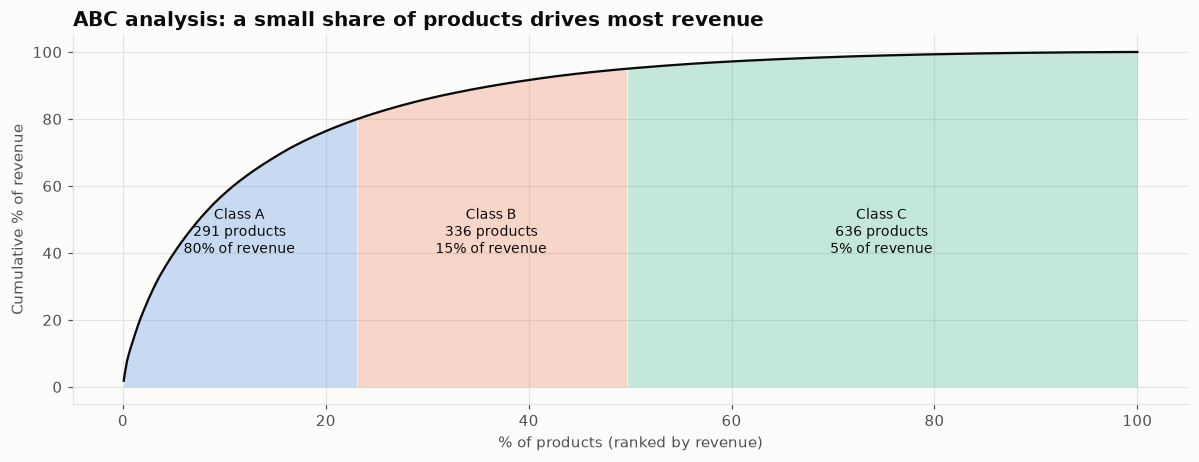

In [26]:
fig, ax = plt.subplots(figsize=(11, 4.3))
x = np.arange(1, len(prod) + 1) / len(prod) * 100
colors_abc = {"A": vs.BLUE, "B": vs.ORANGE, "C": vs.AQUA}
for k, g in prod.groupby("abc_class"):
    ax.fill_between(x[g.index], 0, g["cum_share"], color=colors_abc[k], alpha=0.25, linewidth=0)
ax.plot(x, prod["cum_share"], color=vs.TEXT, linewidth=1.5)
for k, row in abc.iterrows():
    ax.text(prod.index[prod["abc_class"] == k].to_numpy().mean() / len(prod) * 100, 40,
            f"Class {k}\n{row['products']:.0f} products\n{row['revenue_share_pct']:.0f}% of revenue",
            ha="center", fontsize=9, color=vs.TEXT)
ax.set_xlabel("% of products (ranked by revenue)"); ax.set_ylabel("Cumulative % of revenue")
ax.set_title("ABC analysis: a small share of products drives most revenue")
fig.tight_layout(); vs.save(fig, "15_abc_analysis.png"); plt.show()

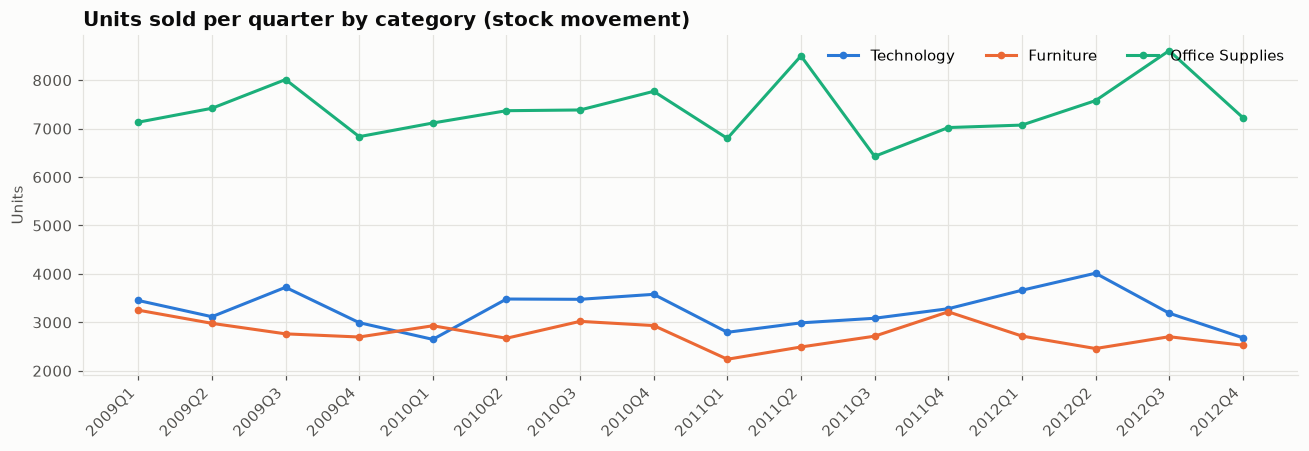

In [27]:
# Quarterly units moved by category (stock movement over time)
qcat = df.pivot_table(index=df["order_date"].dt.to_period("Q").astype(str), columns="category",
                      values="quantity", aggfunc="sum")
fig, ax = plt.subplots(figsize=(12, 4.2))
for c in CATS:
    ax.plot(qcat.index, qcat[c], color=vs.CATEGORY_COLORS[c], marker="o", markersize=4, label=c)
ax.set_title("Units sold per quarter by category (stock movement)"); ax.set_ylabel("Units")
ax.legend(ncol=3, loc="upper right"); plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout(); vs.save(fig, "16_stock_movement_quarterly.png"); plt.show()

In [28]:
# Inventory watch-lists
fast_movers = prod.nlargest(10, "units_per_month")[["product_name", "category", "units", "units_per_month",
                                                     "demand_cv", "abc_class", "margin_pct"]]
slow_movers = prod[(prod["orders"] <= 2)].sort_values("revenue")
high_volume_loss = prod[(prod["units"] >= prod["units"].quantile(0.75)) & (prod["profit"] < 0)] \
    .sort_values("profit")[["product_name", "category", "sub_category", "units", "revenue", "profit", "margin_pct"]]
erratic_A = prod[(prod["abc_class"] == "A") & (prod["demand_cv"] > 1.5)]

metrics["inventory"] = {
    "slow_movers_count": int(len(slow_movers)),
    "slow_movers_revenue_share_pct": round(slow_movers["revenue"].sum() / total_revenue * 100, 2),
    "high_volume_loss_count": int(len(high_volume_loss)),
    "high_volume_loss_total": round(high_volume_loss["profit"].sum(), 2),
    "erratic_A_count": int(len(erratic_A)),
    "median_demand_cv": round(prod["demand_cv"].median(), 2),
    "fast_movers": fast_movers.round(2).to_dict("records"),
    "high_volume_loss_top10": high_volume_loss.head(10).round(2).to_dict("records"),
}
prod.to_csv("../results/product_summary.csv", index=False)
print(f"Slow movers (sold in <=2 orders): {len(slow_movers)}")
print(f"High-volume products that lose money: {len(high_volume_loss)}")
print(f"Class-A products with erratic demand (CV>1.5): {len(erratic_A)}")
fast_movers

Slow movers (sold in <=2 orders): 141
High-volume products that lose money: 140
Class-A products with erratic demand (CV>1.5): 169


,product_name,category,units,units_per_month,demand_cv,abc_class,margin_pct
1202,Crayola Colored Pencils,Office Supplies,70,70.00,4.00,C,17.95
991,Round Specialty Laser Printer Labels,Office Supplies,65,65.00,4.00,C,50.59
333,"Tennsco Stur-D-Stor Boltless Shelving, 5 Shelv...",Office Supplies,76,64.26,4.00,B,-13.79
1044,Sterilite Officeware Hinged File Box,Office Supplies,63,63.00,4.00,C,-30.38
1026,Staples Premium Bright 1-Part Blank Computer P...,Office Supplies,56,56.00,4.00,C,6.49
1157,Eldon® 200 Class™ Desk Accessories,Furniture,55,55.00,4.00,C,-28.12
587,R289LX,Technology,48,48.00,4.00,B,21.64
1249,"Sanford Uni-Blazer™ View Highlighters, Chisel ...",Office Supplies,48,48.00,4.00,C,4.08
662,"Acco Smartsocket™ Table Surge Protector, 6 Col...",Office Supplies,47,47.00,4.00,C,31.58
795,"Electrix Incandescent Magnifying Lamp, Black",Furniture,47,47.00,4.00,C,-27.34


In [29]:
high_volume_loss.head(10)

,product_name,category,sub_category,units,revenue,profit,margin_pct
30,"Global High-Back Leather Tilter, Burgundy",Furniture,Chairs & Chairmats,666,"82,752.20","-30,518.90",-36.88
643,Hoover Portapower™ Portable Vacuum,Office Supplies,Appliances,465,"2,946.43","-21,088.48",-715.73
171,KI Conference Tables,Furniture,Tables,323,"23,289.69","-15,701.27",-67.42
18,BoxOffice By Design Rectangular and Half-Moon ...,Furniture,Tables,516,"104,483.14","-14,938.68",-14.30
186,"Lesro Sheffield Collection Coffee Table, End T...",Furniture,Tables,320,"21,903.78","-14,415.82",-65.81
303,Hon iLevel™ Computer Training Table,Furniture,Tables,379,"11,799.02","-13,214.76",-112.00
463,"Tennsco Lockers, Gray",Office Supplies,Storage & Organization,267,"6,058.66","-12,469.63",-205.81
103,Bevis Steel Folding Chairs,Furniture,Chairs & Chairmats,341,"38,856.90","-10,251.77",-26.38
45,Bush Mission Pointe Library,Furniture,Bookcases,442,"65,244.45","-10,219.79",-15.66
164,"Bush Westfield Collection Bookcases, Dark Cher...",Furniture,Bookcases,237,"24,189.28","-10,096.55",-41.74


## 8 · Correlation between numerical variables

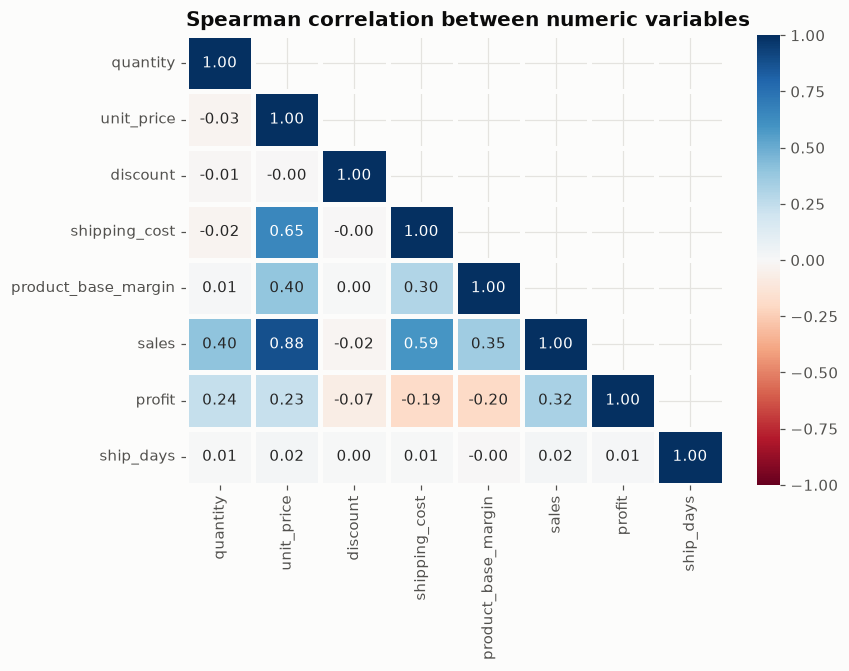

In [30]:
num = df[["quantity", "unit_price", "discount", "shipping_cost", "product_base_margin",
          "sales", "profit", "ship_days"]]
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(corr, cmap="RdBu", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            linewidths=2, linecolor=vs.SURFACE, ax=ax, mask=np.triu(np.ones_like(corr, dtype=bool), 1))
ax.set_title("Spearman correlation between numeric variables")
fig.tight_layout(); vs.save(fig, "17_correlation_heatmap.png"); plt.show()
metrics["correlation_with_profit"] = corr["profit"].drop("profit").round(3).to_dict()

## 9 · Save all metrics

In [31]:
def to_native(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, (pd.Timestamp,)): return str(o.date())
    return str(o)

with open("../results/eda_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=to_native)
print("Saved results/eda_metrics.json with", len(metrics), "sections")

Saved results/eda_metrics.json with 25 sections


## Key EDA findings
These are summarised automatically from the computed metrics, so they always match the data.

In [32]:
k = metrics["kpis"]; y = yearly; c = cat; s = sub.set_index("sub_category")
lines = [
    f"Total revenue ${k['total_revenue']:,.0f}; profit ${k['total_profit']:,.0f} "
    f"({k['profit_margin_pct']:.1f}% margin); {k['total_orders']:,} orders; AOV ${k['avg_order_value']:,.0f}.",
    f"Best revenue year: {y['revenue'].idxmax()} (${y['revenue'].max():,.0f}); "
    f"weakest: {y['revenue'].idxmin()} (${y['revenue'].min():,.0f}).",
    f"Highest-revenue category: {c.index[0]} ({c['revenue_share_pct'].iloc[0]:.1f}% of revenue). "
    f"Highest margin: {c['margin_pct'].idxmax()} ({c['margin_pct'].max():.1f}%).",
    f"Loss-making sub-categories: {', '.join(s.index[s['profit'] < 0])}.",
    f"Top province by revenue: {prov.iloc[0]['province']}; lowest margin: "
    f"{prov.sort_values('margin_pct').iloc[0]['province']} ({prov['margin_pct'].min():.1f}%).",
    f"Top 20% of customers generate {top20_share:.1f}% of revenue; {repeat_share:.1f}% of customers are repeat buyers.",
    f"Margin at 0-2% discount: {disc['margin_pct'].iloc[0]:.1f}% vs 9%+ discount: {disc['margin_pct'].iloc[-1]:.1f}%.",
    f"Class-A products: {abc.loc['A','products']:.0f} of {abc['products'].sum():.0f} "
    f"({abc.loc['A','product_share_pct']:.0f}%) generate 80% of revenue.",
]
for l in lines: print("•", l)

• Total revenue $14,915,601; profit $1,521,768 (10.2% margin); 5,496 orders; AOV $2,714.
• Best revenue year: 2009 ($4,209,139); weakest: 2011 ($3,436,817).
• Highest-revenue category: Technology (40.1% of revenue). Highest margin: Technology (14.8%).
• Loss-making sub-categories: Tables, Bookcases, Scissors, Rulers and Trimmers, Rubber Bands.
• Top province by revenue: Ontario; lowest margin: Nunavut (2.4%).
• Top 20% of customers generate 46.5% of revenue; 98.6% of customers are repeat buyers.
• Margin at 0-2% discount: 12.4% vs 9%+ discount: 7.5%.
• Class-A products: 291 of 1263 (23%) generate 80% of revenue.
